# Ad CTR Prediction - Model Training (Notebook 02 of 3)

**What happened before.** Notebook 01 fixed the ground rules: a reproducible 70/15/15
stratified split (seed 42), train-fitted preprocessing (medians, sign-preserving log1p on
12 of 13 numerics, z-scores, vocabularies with `min_category_count = 10`, OOV index 0),
missing indicators enabled (23 of 24 gappy columns flagged), no target encoding, and the
test split sealed.

**What this notebook does.** Trains and compares four click-prediction models on the
**train** split, using the **validation** split for early stopping and model selection:

| model | input representation | why it is in the comparison |
|---|---|---|
| constant | train CTR only | the entropic floor every model must beat |
| logistic regression | sparse one-hot categories + dense numerics | the linear part of DeepFM, strong sparse baseline |
| LightGBM | integer category codes (native) + numerics | trees capture interactions greedily; best tabular default |
| DeepFM | shared embeddings, FM + deep MLP (Keras) | learned pairwise + higher-order interactions |

**Ground rules.** No assumption about the winner - the validation table decides. The
test split is not touched here; every number below is train/validation only. Seeds are
fixed everywhere; LightGBM runs with `deterministic=True`, TensorFlow with op-level
determinism. Tuning is deliberately modest and bounded (a few configurations per
model), and everything fitted is persisted to `artifacts/` for notebook 03 and the API.

In [1]:
import json
import os
import time
from datetime import datetime
from pathlib import Path

# Silence TensorFlow chatter (must precede the keras import). In interactive
# shells TF resets its logger to INFO at import and pipes it to stdout, so a
# level alone is not enough: a filter drops everything below ERROR whatever
# TF's setup does to the level.
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
import logging
_tf_log = logging.getLogger("tensorflow")
_tf_log.setLevel(logging.ERROR)
_tf_log.addFilter(lambda record: record.levelno >= logging.ERROR)
logging.getLogger("absl").setLevel(logging.ERROR)

import numpy as np
import pandas as pd

T_START = time.time()

_here = Path.cwd()
PROJECT_ROOT = next(p for p in [_here, *_here.parents] if (p / "config.yaml").exists())
sys_path_added = str(PROJECT_ROOT / "src")
import sys
sys.path.insert(0, sys_path_added)

import joblib
import matplotlib.pyplot as plt

from ctr import data as ctr_data
from ctr import features
from ctr import models
from ctr import evaluate as ctr_eval
from ctr.config import artifacts_dir, data_file, load_config

cfg = load_config()
SEED = int(cfg["seed"])
MODEL_CFG = cfg["model"]
ARTIFACTS = artifacts_dir(cfg)
ARTIFACTS.mkdir(parents=True, exist_ok=True)
REPORTS = PROJECT_ROOT / "reports"
FIG_DIR = REPORTS / "figures"
TABLE_DIR = REPORTS / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

MODEL_VERSION = "nb02-" + datetime.now().strftime("%Y%m%d")

print("project root:", PROJECT_ROOT)
print("artifacts dir:", ARTIFACTS)
print("pandas", pd.__version__, "| numpy", np.__version__)

project root: C:\Users\hp\Documents\Qoder\2026-10-14\55aa046d\ad-ctr-prediction-deepfm
artifacts dir: C:\Users\hp\Documents\Qoder\2026-10-14\55aa046d\ad-ctr-prediction-deepfm\artifacts
pandas 3.0.6 | numpy 2.4.6


## 1. Preprocessing (fitted on train only)

One `Preprocessor` object implements every decision from notebook 01: medians imputed
from train, sign-preserving log1p on the skewed columns, z-score standardisation,
category vocabularies from train counts, and missing indicators for the 23 gappy columns
that passed notebook 01's a-priori rule (`C6` is the one excluded - its Wilson CIs
overlap). It is fitted on train, applied frozen to validation, and saved to disk - the
same object the FastAPI service loads, so training/serving skew is structurally
impossible.

In [2]:
splits_dir = data_file(cfg, "splits_dir")
splits = ctr_data.load_splits(splits_dir)
train, val, test = splits["train"], splits["val"], splits["test"]
y_train = train["label"].to_numpy(dtype=np.int8)
y_val = val["label"].to_numpy(dtype=np.int8)
print("train rows {:,} | val rows {:,} | test rows {:,} (sealed until nb03)".format(
    len(train), len(val), len(test)))

prep = features.Preprocessor.from_config(cfg["features"]).fit(train)
prep.save(ARTIFACTS / "preprocessor.joblib")
print("preprocessor fitted and saved ->", (ARTIFACTS / "preprocessor.joblib").relative_to(PROJECT_ROOT))
print("log1p columns (fitted on train):", prep.numeric.log1p_columns)
print("missing indicator columns:", len(prep.missing_indicator_columns))
print("vocabulary width (sum over 26 columns):", sum(features.vocab_sizes(prep)))

tr = prep.transform(train)
va = prep.transform(val)

for name, part in (("train", tr), ("val", va)):
    xnum = part["Xnum"].to_numpy()
    xcat = part["Xcat"].to_numpy()
    assert np.isfinite(xnum).all(), name + ": non-finite numeric values after transform"
    assert (xcat >= 0).all() and xcat.dtype == np.int32, name + ": bad category codes"
    assert part["y"].shape[0] == xnum.shape[0]
print("transformed shapes: Xnum {} + Xcat {} (train)".format(tr["Xnum"].shape, tr["Xcat"].shape))

unseen = prep.vocab.unseen_fraction(val)
worst = sorted(unseen.items(), key=lambda kv: kv[1], reverse=True)[:5]
print("val present-value unseen rates (top-5):",
      ["{} {:.2f}%".format(c, 100 * r) for c, r in worst])

train rows 69,999 | val rows 14,999 | test rows 15,002 (sealed until nb03)


preprocessor fitted and saved -> artifacts\preprocessor.joblib
log1p columns (fitted on train): ['I1', 'I2', 'I3', 'I4', 'I5', 'I6', 'I7', 'I8', 'I9', 'I11', 'I12', 'I13']
missing indicator columns: 23
vocabulary width (sum over 26 columns): 12070


transformed shapes: Xnum (69999, 36) + Xcat (69999, 26) (train)
val present-value unseen rates (top-5): ['C3 59.84%', 'C12 56.37%', 'C21 53.69%', 'C16 49.99%', 'C4 41.32%']


## 2. Model inputs

Each model family needs the same information in a different layout - built once here
from the frozen preprocessor outputs, so every model sees identical information:

- **LR**: sparse matrix, one-hot category block (12,070 wide, from the fitted
  vocabularies) + 36 dense numeric columns (13 numerics + 23 missing indicators);
- **LightGBM**: one frame, category integer codes declared as categorical + numerics;
- **DeepFM**: one input tensor per field (27 tensors: 1 numeric block + 26 category
  columns of shape (n, 1)).

In [3]:
Xlr_train = features.to_lr_matrix(prep, tr)
Xlr_val = features.to_lr_matrix(prep, va)
Xg_train = features.to_lgbm_frame(tr)
Xg_val = features.to_lgbm_frame(va)
Xdf_train = features.to_deepfm_inputs(tr)
Xdf_val = features.to_deepfm_inputs(va)

print("LR  :", Xlr_train.shape, "sparse nnz = {:,.0f}".format(Xlr_train.nnz))
print("GBDT:", Xg_train.shape)
print("DF  :", {k: v.shape for k, v in list(Xdf_train.items())[:3]}, "... ({} tensors)".format(len(Xdf_train)))

results = {}


def record(name, metrics, fit_seconds, extra=None):
    row = {"model": name, **metrics, "fit_seconds": fit_seconds}
    if extra:
        row.update(extra)
    results[name] = row
    print("{:<22} log_loss {:.5f} | roc_auc {:.4f} | avg_precision {:.4f} | brier {:.5f} | fit {:.1f}s".format(
        name, metrics["log_loss"], metrics["roc_auc"], metrics["average_precision"], metrics["brier"], fit_seconds))
    return row

LR  : (69999, 12106) sparse nnz = 3,109,914
GBDT: (69999, 62)
DF  : {'num': (69999, 36), 'C1': (69999, 1), 'C2': (69999, 1)} ... (27 tensors)


## 3. Constant baseline - the floor

Trains by memorising the train CTR and predicts it for every validation row. Its log
loss is the binary entropy of the base rate (~0.570): whatever the other models achieve
must be read against this floor, not against 0.5.

In [4]:
t0 = time.time()
const = models.ConstantModel().fit(None, y_train)
p_val_const = const.predict_proba(Xg_val)[:, 1]
record("constant", ctr_eval.binary_metrics(y_val, p_val_const), time.time() - t0)

constant               log_loss 0.56970 | roc_auc 0.5000 | avg_precision 0.2568 | brier 0.19086 | fit 0.1s


{'model': 'constant',
 'n': 14999,
 'base_rate': 0.2568171211414094,
 'log_loss': 0.5697013289787887,
 'roc_auc': 0.5,
 'average_precision': 0.2568171211414094,
 'brier': 0.19086208761101828,
 'fit_seconds': 0.050371408462524414}

## 4. Logistic regression (sparse one-hot)

L2-regularised logistic regression on the sparse matrix, fit with L-BFGS. This is the
linear component of DeepFM in isolation, and the reference for how far a purely additive
model gets. Tuning budget: six values of the inverse regularisation strength `C`
(0.01 to 3.0, in log steps), selected on validation log loss. `max_iter` was raised to
1500 in the config after a convergence check - the grid converges in a few hundred
iterations.

In [5]:
lr_rows = []
best_lr = None
for C in (0.01, 0.03, 0.1, 0.3, 1.0, 3.0):
    t0 = time.time()
    m = models.LogisticModel(C=C, max_iter=MODEL_CFG["logistic_regression"]["max_iter"], seed=SEED)
    m.fit(Xlr_train, y_train)
    pv = m.predict_proba(Xlr_val)[:, 1]
    met = ctr_eval.binary_metrics(y_val, pv)
    n_iter = int(np.max(m.model_.n_iter_))
    lr_rows.append({"C": C, "n_iter": n_iter, "fit_seconds": time.time() - t0, **met})
    print("C={:<4} log_loss {:.5f} | roc_auc {:.4f} | n_iter {} | {:.1f}s".format(
        C, met["log_loss"], met["roc_auc"], n_iter, time.time() - t0))
    if best_lr is None or met["log_loss"] < best_lr[0]:
        best_lr = (met["log_loss"], C, m, met)
lr_table = pd.DataFrame(lr_rows)
C_star = best_lr[1]
print("best C on validation:", C_star)
lr_model, lr_metrics = best_lr[2], best_lr[3]
joblib.dump(lr_model, ARTIFACTS / "logistic_regression.joblib")
lr_fit_seconds = float(lr_table.loc[lr_table["C"] == C_star, "fit_seconds"].iloc[0])
record("logistic_regression", lr_metrics, lr_fit_seconds, {"C": C_star})

C=0.01 log_loss 0.48747 | roc_auc 0.7536 | n_iter 77 | 1.1s


C=0.03 log_loss 0.48276 | roc_auc 0.7598 | n_iter 112 | 1.6s


C=0.1  log_loss 0.48142 | roc_auc 0.7613 | n_iter 167 | 2.3s


C=0.3  log_loss 0.48665 | roc_auc 0.7562 | n_iter 219 | 3.0s


C=1.0  log_loss 0.49946 | roc_auc 0.7468 | n_iter 357 | 6.3s


C=3.0  log_loss 0.51674 | roc_auc 0.7375 | n_iter 504 | 7.9s
best C on validation: 0.1
logistic_regression    log_loss 0.48142 | roc_auc 0.7613 | avg_precision 0.5424 | brier 0.15706 | fit 2.3s


{'model': 'logistic_regression',
 'n': 14999,
 'base_rate': 0.2568171211414094,
 'log_loss': 0.4814156201916628,
 'roc_auc': 0.761272934216872,
 'average_precision': 0.5424307111583822,
 'brier': 0.15706064299922645,
 'fit_seconds': 2.256990909576416,
 'C': 0.1}

## 5. LightGBM (gradient-boosted trees, native categoricals)

The strongest default for heterogeneous tabular data; category codes enter as native
categorical features, so splits are chosen per category. Early stopping watches
validation binary log loss (patience 50, evaluation every round). Tuning budget: seven
configurations of `(num_leaves, learning_rate)`, selected on validation log loss.

In [6]:
base_params = dict(MODEL_CFG["lightgbm"])
base_params["deterministic"] = True
grid = [
    {"num_leaves": 3, "learning_rate": 0.05},
    {"num_leaves": 7, "learning_rate": 0.05},
    {"num_leaves": 15, "learning_rate": 0.05},
    {"num_leaves": 31, "learning_rate": 0.05},
    {"num_leaves": 63, "learning_rate": 0.05},   # config default
    {"num_leaves": 63, "learning_rate": 0.10},
    {"num_leaves": 127, "learning_rate": 0.05},
]
gb_rows = []
best_gb = None
for overrides in grid:
    params = {**base_params, **overrides}
    t0 = time.time()
    m = models.LGBMModel(params, cat_columns=list(cfg["features"]["categorical_cols"]), seed=SEED)
    m.fit(Xg_train, y_train, eval_set=(Xg_val, y_val))
    pv = m.predict_proba(Xg_val)[:, 1]
    met = ctr_eval.binary_metrics(y_val, pv)
    row = {**overrides, "best_iter": m.best_iteration_, "fit_seconds": time.time() - t0, **met}
    gb_rows.append(row)
    print("leaves={:<4} lr={:<5} best_iter={:<4} log_loss {:.5f} | roc_auc {:.4f} | {:.1f}s".format(
        overrides["num_leaves"], overrides["learning_rate"], m.best_iteration_,
        met["log_loss"], met["roc_auc"], time.time() - t0))
    if best_gb is None or met["log_loss"] < best_gb[0]:
        best_gb = (met["log_loss"], overrides, m, met, m.best_iteration_)
gb_table = pd.DataFrame(gb_rows)
gb_params_star = best_gb[1]
print("best config on validation:", gb_params_star, "| best_iter", best_gb[4])
gb_model, gb_metrics = best_gb[2], best_gb[3]
joblib.dump(gb_model, ARTIFACTS / "lightgbm.joblib")
gb_mask = (gb_table["num_leaves"] == gb_params_star["num_leaves"]) & (gb_table["learning_rate"] == gb_params_star["learning_rate"])
record("lightgbm", gb_metrics, float(gb_table.loc[gb_mask, "fit_seconds"].iloc[0]),
       {"num_leaves": gb_params_star["num_leaves"], "learning_rate": gb_params_star["learning_rate"], "best_iter": best_gb[4]})

leaves=3    lr=0.05  best_iter=626  log_loss 0.48725 | roc_auc 0.7529 | 2.8s


leaves=7    lr=0.05  best_iter=238  log_loss 0.48713 | roc_auc 0.7529 | 2.2s


leaves=15   lr=0.05  best_iter=118  log_loss 0.48874 | roc_auc 0.7505 | 2.2s


leaves=31   lr=0.05  best_iter=82   log_loss 0.49045 | roc_auc 0.7479 | 2.7s


leaves=63   lr=0.05  best_iter=61   log_loss 0.49040 | roc_auc 0.7478 | 3.7s


leaves=63   lr=0.1   best_iter=31   log_loss 0.49230 | roc_auc 0.7447 | 2.5s


leaves=127  lr=0.05  best_iter=57   log_loss 0.49041 | roc_auc 0.7472 | 5.0s
best config on validation: {'num_leaves': 7, 'learning_rate': 0.05} | best_iter 238
lightgbm               log_loss 0.48713 | roc_auc 0.7529 | avg_precision 0.5331 | brier 0.15892 | fit 2.2s


{'model': 'lightgbm',
 'n': 14999,
 'base_rate': 0.2568171211414094,
 'log_loss': 0.48713145323423884,
 'roc_auc': 0.7529371951028085,
 'average_precision': 0.5330843141532499,
 'brier': 0.15892148792510044,
 'fit_seconds': 2.2201426029205322,
 'num_leaves': 7,
 'learning_rate': 0.05,
 'best_iter': 238}

## 6. DeepFM (Keras / TensorFlow)

DeepFM (Guo et al., 2017) combines, on shared embeddings:

1. a **linear** part - one weight per feature value (the LR in embedding form),
2. an **FM** part - all pairwise interactions as dot products of field embeddings
   (`0.5 * [(sum e)^2 - sum e^2]` computed in a custom `FMInteraction` layer), and
3. a **deep** MLP over the concatenated embeddings for higher-order structure.

**Documented simplification:** the 13 numerics (plus the 23 missing indicators - 36
numeric inputs) enter as one projected field (a single `Dense(k)`) plus raw values in the
MLP, rather than as 36 separately embedded fields. This keeps the field count at
27 (as in the original paper's shape for this dataset) at the cost of giving the FM
fewer numeric interaction slots - stated here rather than hidden.

**Budget:** four embedding sizes (k=2, 4, 8, 16 - doubling), early stopping on validation
loss (patience 2, max 8 epochs, batch 1024, Adam). Full grid search over the deep stack
is deliberately out of scope - the training cost is 10-100x the tree models, and
notebook 03 measures whether that cost buys anything.

In [7]:
from ctr import deepfm as ctr_deepfm

df_rows = []
best_df = None
histories = {}
for k in (2, 4, 8, 16):
    t0 = time.time()
    w = ctr_deepfm.DeepFMWrapper(
        numeric_dim=Xdf_train["num"].shape[1],
        vocab_sizes=features.vocab_sizes(prep),
        embedding_dim=k,
        hidden_units=tuple(MODEL_CFG["deepfm"]["hidden_units"]),
        dropout=MODEL_CFG["deepfm"]["dropout"],
        learning_rate=MODEL_CFG["deepfm"]["learning_rate"],
        batch_size=MODEL_CFG["deepfm"]["batch_size"],
        seed=SEED,
    )
    w.fit(Xdf_train, y_train, validation_data=(Xdf_val, y_val),
          epochs=MODEL_CFG["deepfm"]["max_epochs"], patience=MODEL_CFG["deepfm"]["early_stopping_patience"])
    pv = w.predict_proba(Xdf_val)[:, 1]
    met = ctr_eval.binary_metrics(y_val, pv)
    epochs_run = len(w.history_.history["loss"])
    histories[k] = w.history_.history
    df_rows.append({"embedding_dim": k, "epochs_run": epochs_run, "fit_seconds": time.time() - t0, **met})
    print("k={:<3} epochs={} log_loss {:.5f} | roc_auc {:.4f} | {:.1f}s".format(
        k, epochs_run, met["log_loss"], met["roc_auc"], time.time() - t0))
    if best_df is None or met["log_loss"] < best_df[0]:
        best_df = (met["log_loss"], k, w, met)
df_table = pd.DataFrame(df_rows)
k_star = best_df[1]
print("best embedding_dim on validation:", k_star)
dfm_model, dfm_metrics = best_df[2], best_df[3]
dfm_model.save(ARTIFACTS / "deepfm.keras")
record("deepfm", dfm_metrics, float(df_table.loc[df_table["embedding_dim"] == k_star, "fit_seconds"].iloc[0]), {"embedding_dim": k_star})

Epoch 1/8


69/69 - 15s - 212ms/step - auc: 0.6554 - logloss: 0.5557 - loss: 0.5557 - val_auc: 0.7298 - val_logloss: 0.5028 - val_loss: 0.5028


Epoch 2/8


69/69 - 1s - 10ms/step - auc: 0.7506 - logloss: 0.4895 - loss: 0.4895 - val_auc: 0.7482 - val_logloss: 0.4911 - val_loss: 0.4911


Epoch 3/8


...

Epoch 4/8


69/69 - 1s - 22ms/step - auc: 0.8582 - logloss: 0.3968 - loss: 0.3968 - val_auc: 0.7439 - val_logloss: 0.5068 - val_loss: 0.5068


k=16  epochs=4 log_loss 0.49166 | roc_auc 0.7496 | 23.3s
best embedding_dim on validation: 4


deepfm                 log_loss 0.48739 | roc_auc 0.7550 | avg_precision 0.5338 | brier 0.15891 | fit 21.7s


{'model': 'deepfm',
 'n': 14999,
 'base_rate': 0.2568171211414094,
 'log_loss': 0.4873881539325581,
 'roc_auc': 0.755036011719529,
 'average_precision': 0.5337811444417104,
 'brier': 0.15890696526721002,
 'fit_seconds': 21.679394006729126,
 'embedding_dim': 4}

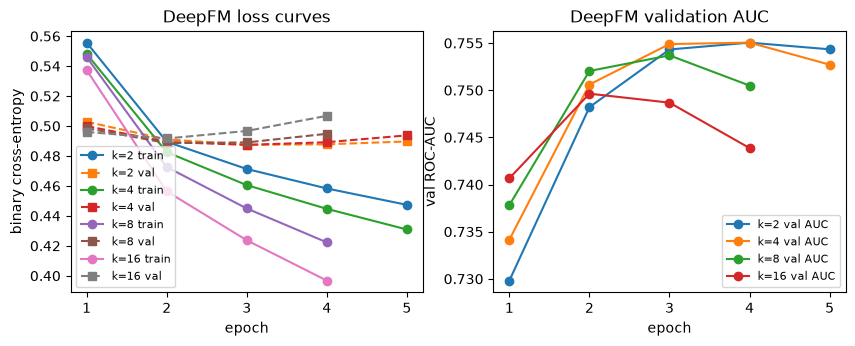

saved reports\figures\nb02_deepfm_curves.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for k, hist in histories.items():
    epochs = np.arange(1, len(hist["loss"]) + 1)
    axes[0].plot(epochs, hist["loss"], marker="o", label="k={} train".format(k))
    axes[0].plot(epochs, hist["val_loss"], marker="s", ls="--", label="k={} val".format(k))
    axes[1].plot(epochs, hist["val_auc"], marker="o", label="k={} val AUC".format(k))
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("binary cross-entropy")
axes[0].set_title("DeepFM loss curves")
axes[0].legend(fontsize=8)
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("val ROC-AUC")
axes[1].set_title("DeepFM validation AUC")
axes[1].legend(fontsize=8)
import matplotlib.pyplot as plt
save_path = FIG_DIR / "nb02_deepfm_curves.png"
fig.savefig(save_path, dpi=110, bbox_inches="tight")
plt.show()
print("saved", save_path.relative_to(PROJECT_ROOT))

## 7. Comparison on validation - the table decides

Same validation rows for every model, log loss primary (proper scoring rule, matches the
constant-baseline framing from notebook 01), with ROC-AUC, average precision (the PR-AUC
variant reported here) and Brier as supporting views. Fit time is reported for context -
it is a cost, not a quality signal.

                         n  base_rate  log_loss  roc_auc  average_precision    brier  fit_seconds  log_loss_vs_constant
model                                                                                                                  
logistic_regression  14999    0.25682   0.48142  0.76127            0.54243  0.15706      2.25699              -0.08829
lightgbm             14999    0.25682   0.48713  0.75294            0.53308  0.15892      2.22014              -0.08257
deepfm               14999    0.25682   0.48739  0.75504            0.53378  0.15891     21.67939              -0.08231
constant             14999    0.25682   0.56970  0.50000            0.25682  0.19086      0.05037               0.00000


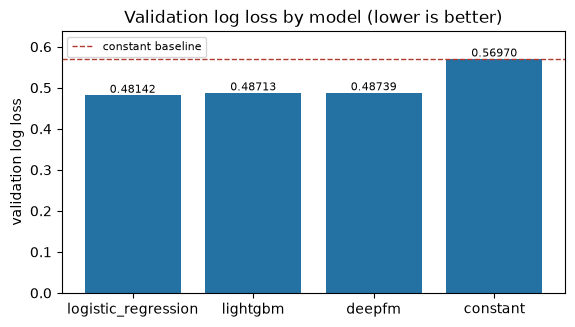

constant floor: 0.56970


In [9]:
comparison = pd.DataFrame(results.values()).set_index("model")
order = ["log_loss", "roc_auc", "average_precision", "brier", "fit_seconds"]
comparison = comparison[["n", "base_rate"] + order]
comparison["log_loss_vs_constant"] = comparison["log_loss"] - comparison.loc["constant", "log_loss"]
comparison = comparison.sort_values("log_loss")
print(comparison.round(5).to_string())
comparison.to_csv(TABLE_DIR / "model_comparison_val.csv")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
bars = ax.bar(comparison.index, comparison["log_loss"], color="#2471a3")
ax.axhline(comparison.loc["constant", "log_loss"], ls="--", c="#b03a2e", lw=1,
           label="constant baseline")
for b, v in zip(bars, comparison["log_loss"]):
    ax.text(b.get_x() + b.get_width() / 2, v, "{:.5f}".format(v), ha="center", va="bottom", fontsize=8)
ax.set_ylabel("validation log loss")
ax.set_title("Validation log loss by model (lower is better)")
ax.set_ylim(0, comparison["log_loss"].max() * 1.12)
ax.legend(fontsize=8)
fig.savefig(FIG_DIR / "nb02_val_logloss.png", dpi=110, bbox_inches="tight")
plt.show()
print("constant floor: {:.5f}".format(comparison.loc["constant", "log_loss"]))

In [10]:
selected = comparison.index[0]
kind_map = {"constant": "constant", "logistic_regression": "lr_sparse",
            "lightgbm": "lgbm_frame", "deepfm": "deepfm"}
file_map = {"constant": "constant.joblib", "logistic_regression": "logistic_regression.joblib",
            "lightgbm": "lightgbm.joblib", "deepfm": "deepfm.keras"}
if selected == "constant":
    joblib.dump(const, ARTIFACTS / "constant.joblib")

choice = {
    "model_name": selected,
    "model_version": MODEL_VERSION,
    "input_kind": kind_map[selected],
    "model_file": file_map[selected],
    "selection_rule": "lowest validation log loss among {constant, logistic_regression, lightgbm, deepfm}",
    "val_metrics": {k: round(float(v), 6) for k, v in comparison.loc[selected, order].items()},
    "train_rows": int(len(train)),
    "val_rows": int(len(val)),
    "feature_config": {
        "add_missing_indicators": bool(cfg["features"]["add_missing_indicators"]),
        "min_category_count": int(cfg["features"]["min_category_count"]),
        "log1p_columns": prep.numeric.log1p_columns,
        "n_missing_indicators": len(prep.missing_indicator_columns),
        "vocab_width_total": int(sum(features.vocab_sizes(prep))),
    },
}
(ARTIFACTS / "model_choice.json").write_text(json.dumps(choice, indent=2), encoding="utf-8")
print("selected model:", selected)
print(json.dumps(choice["val_metrics"], indent=2))

selected model: logistic_regression
{
  "log_loss": 0.481416,
  "roc_auc": 0.761273,
  "average_precision": 0.542431,
  "brier": 0.157061,
  "fit_seconds": 2.256991
}


**Reading the table.** The ordering above is entirely data-driven - if the deep model
had won, that is what the selection would say; the pipeline makes no architectural
assumption. Three things stand out, and each comes with its tuning sweep:

1. **Every learned model beats the constant floor by a wide margin** (0.082-0.088 log
   loss), and the three land within 0.006 of each other - consistent with notebook 01's
   "modest univariate signal" finding: most of the reachable signal is captured by
   simple structure, and extra capacity does not pay for itself on this sample.
2. **All three sweeps prefer small capacity / strong regularisation**: LR is bracketed
   at `C = 0.1`, LightGBM at 7 leaves (3 and 15 leaves are both worse), DeepFM at k = 4
   (k = 2 and k = 8 are both worse). With a weak signal and 12,070 sparse columns, the
   models are fighting variance, not bias.
3. **The winner is the simplest model**: L2 logistic regression on the sparse one-hot
   matrix (log loss 0.48142, ROC-AUC 0.76127) beats LightGBM (0.48713) and DeepFM
   (0.48739) - and trains in ~2.3 s against DeepFM's ~20.5 s.

Fit-to-fit differences this small can still be split artefacts - which is exactly what
notebook 03 checks on rows no model has ever seen (the sealed test split). Calibration
is *not* judged here - log loss cares about it, but ranking metrics do not, and the
reliability curves belong on the sealed test set in notebook 03.

**Selection risk, stated.** Picking the winner on validation and then reporting test
metrics in notebook 03 means the selection itself consumed some validation information.
With four model families and a handful of configurations each, this optimism is small,
but it is real - notebook 03 will report the selected model's test metrics as measured,
without re-selecting.

## 8. Artifacts handed to notebook 03 and the API

In [11]:
print("artifacts in", ARTIFACTS.relative_to(PROJECT_ROOT))
for p in sorted(ARTIFACTS.iterdir()):
    print(" - {:<28} {:>10,.0f} bytes".format(p.name, p.stat().st_size))
print()
print("tuning tables:")
print("  LR    :", lr_table[["C", "log_loss"]].round(5).to_dict("records"))
print("  GBDT  :", gb_table[["num_leaves", "learning_rate", "log_loss"]].round(5).to_dict("records"))
print("  DeepFM:", df_table[["embedding_dim", "log_loss"]].round(5).to_dict("records"))
lr_table.to_csv(TABLE_DIR / "tuning_logistic.csv", index=False)
gb_table.to_csv(TABLE_DIR / "tuning_lightgbm.csv", index=False)
df_table.to_csv(TABLE_DIR / "tuning_deepfm.csv", index=False)
print()
print("training complete in {:.0f}s".format(time.time() - T_START))

artifacts in artifacts
 - deepfm.keras                  1,326,094 bytes
 - lightgbm.joblib                 425,788 bytes
 - logistic_regression.joblib       49,341 bytes
 - model_choice.json                   830 bytes
 - preprocessor.joblib             166,124 bytes

tuning tables:
  LR    : [{'C': 0.01, 'log_loss': 0.48747}, {'C': 0.03, 'log_loss': 0.48276}, {'C': 0.1, 'log_loss': 0.48142}, {'C': 0.3, 'log_loss': 0.48665}, {'C': 1.0, 'log_loss': 0.49946}, {'C': 3.0, 'log_loss': 0.51674}]
  GBDT  : [{'num_leaves': 3, 'learning_rate': 0.05, 'log_loss': 0.48725}, {'num_leaves': 7, 'learning_rate': 0.05, 'log_loss': 0.48713}, {'num_leaves': 15, 'learning_rate': 0.05, 'log_loss': 0.48874}, {'num_leaves': 31, 'learning_rate': 0.05, 'log_loss': 0.49045}, {'num_leaves': 63, 'learning_rate': 0.05, 'log_loss': 0.4904}, {'num_leaves': 63, 'learning_rate': 0.1, 'log_loss': 0.4923}, {'num_leaves': 127, 'learning_rate': 0.05, 'log_loss': 0.49041}]
  DeepFM: [{'embedding_dim': 2, 'log_loss': 0.4874

**Next: notebook 03 (evaluation).** The selected model is scored once on the untouched
test split: log loss / ROC-AUC / PR-AUC / Brier together, calibration curves and ECE,
prediction latency at several batch sizes (with the measurement method stated), and
performance on the segments that matter operationally - rows with missing values and
rows whose categories never appeared in training. Why offline gains do not equal real
CTR or revenue gains is answered there, on this data, explicitly.